# Project work, part 4 - Machine learning

GitHub Repository:
<https://github.com/sgkop/IND320-Innlevering-sgkop>

Streamlit App:
<https://ind320-innlevering1-sgkop.streamlit.app/>


## Planned Streamlit Structure

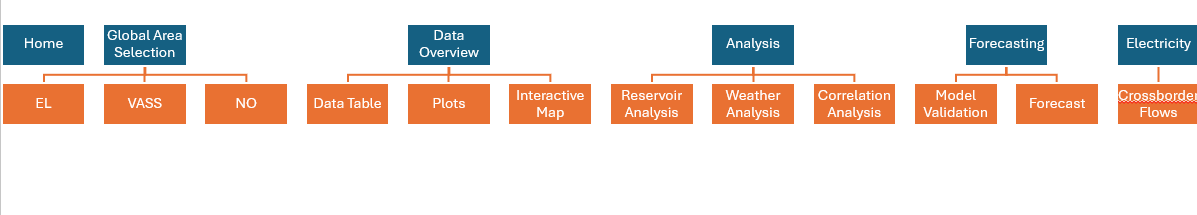

In [1]:
from IPython.display import Image

Image("images/streamlit_structure.png")

The initial application from earlier project parts
was reorganised into four main groups:

- Data Overview
- Analysis
- Forecasting
- Electricity

A shared Session State implementation was introduced
to propagate area selections between the Interactive
Map, Weather Analysis, Reservoir Analysis,
Correlation Analysis and Forecasting pages.

## Norges Bank API

### Purpose

The purpose of this section is to download historical
EUR/NOK and USD/NOK exchange rates from the Norwegian
Bank API and investigate whether currency exchange
rates can be used as explanatory variables in later
forecasting models.

In [22]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [12]:
def download_currency(
    currency,
    start_date,
    end_date
):
    """
    Download historical exchange rates
    from Norges Bank.

    Parameters
    ----------
    currency : str
        EUR or USD.

    start_date : str
        Start date.

    end_date : str
        End date.
    """

    url = (
        "https://data.norges-bank.no/api/data/"
        f"EXR/B.{currency}.NOK.SP"
    )

    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "sdmx-json"
    }

    return requests.get(
        url,
        params=params
    )

In [13]:
eur_test = download_currency(
    "EUR",
    "2024-01-01",
    "2024-12-31"
)

eur_test.status_code

200

In [14]:
eur_json = eur_test.json()

eur_json["data"].keys()

dict_keys(['dataSets', 'structure'])

In [16]:
def currency_dataframe(
    currency,
    start_date,
    end_date
):
    """
    Download and return a
    currency exchange-rate DataFrame.
    """

    ...

In [17]:
def currency_dataframe(
    currency,
    start_date,
    end_date
):
    """
    Download exchange-rate data from Norges Bank
    and return it as a pandas DataFrame.

    Parameters
    ----------
    currency : str
        Currency code such as EUR or USD.

    start_date : str
        Start date (YYYY-MM-DD).

    end_date : str
        End date (YYYY-MM-DD).
    """

    url = (
        "https://data.norges-bank.no/api/data/"
        f"EXR/B.{currency}.NOK.SP"
    )

    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "sdmx-json"
    }

    response = requests.get(
        url,
        params=params
    )

    response.raise_for_status()

    data = response.json()

    observations = (
        data["data"]
        ["dataSets"][0]
        ["series"]["0:0:0:0"]
        ["observations"]
    )

    dates = (
        data["data"]
        ["structure"]
        ["dimensions"]
        ["observation"][0]
        ["values"]
    )

    records = []

    for index, value in observations.items():

        records.append(
            {
                "date": dates[int(index)]["id"],
                "rate": float(value[0])
            }
        )

    df = pd.DataFrame(records)

    df["date"] = pd.to_datetime(
        df["date"]
    )

    return df.sort_values(
        "date"
    )


In [18]:
eur_df = currency_dataframe(
    currency="EUR",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

usd_df = currency_dataframe(
    currency="USD",
    start_date="2024-01-01",
    end_date="2024-12-31"
)


In [19]:
eur_df.head()

,date,rate
0,2024-01-02,11.2815
1,2024-01-03,11.3200
2,2024-01-04,11.2845
3,2024-01-05,11.3090
4,2024-01-08,11.3620


In [20]:
usd_df.head()

,date,rate
0,2024-01-02,10.2971
1,2024-01-03,10.3672
2,2024-01-04,10.3027
3,2024-01-05,10.3553
4,2024-01-08,10.3800


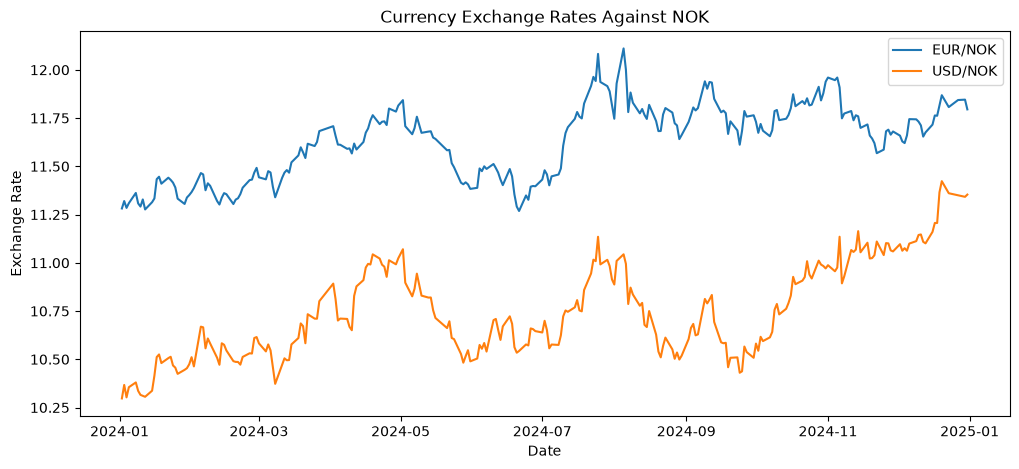

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    eur_df["date"],
    eur_df["rate"],
    label="EUR/NOK"
)

plt.plot(
    usd_df["date"],
    usd_df["rate"],
    label="USD/NOK"
)

plt.title(
    "Currency Exchange Rates Against NOK"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Exchange Rate"
)

plt.legend()

plt.show()

### Findings

Historical EUR/NOK and USD/NOK exchange rates were
successfully downloaded from the Norges Bank API.

Both currencies experienced noticeable fluctuations
during 2024, with EUR/NOK varying approximately
between 11.3 and 12.1 NOK and USD/NOK between
10.3 and 11.4 NOK.

The data are available at daily resolution and can
therefore be aggregated to weekly or monthly values
before being combined with Magasinstatistikk and
weather data in later forecasting models.

The function was implemented as a reusable component
that can be applied to different currencies and time
intervals.

## Timezone Investigation

### Purpose

The purpose of this section is to investigate possible
timezone differences between Magasinstatistikk,
Open-Meteo, ENTSO-E and Norges Bank data.

The findings will be used to assess whether timestamp
adjustments are necessary before combining data from
different sources.


In [31]:
import pandas as pd
import requests

url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

magasin_df = pd.DataFrame(
    requests.get(url).json()
)

magasin_df[
    [
        "dato_Id",
        "iso_aar",
        "iso_uke"
    ]
].head()

,dato_Id,iso_aar,iso_uke
0,2020-11-15,2020,46
1,2011-08-28,2011,34
2,1998-07-05,1998,27
3,2011-03-27,2011,12
4,2017-11-05,2017,44


In [28]:
def sample_weather():

    url = (
        "https://archive-api.open-meteo.com/v1/archive"
    )

    params = {
        "latitude": 63.25,
        "longitude": 9.90,
        "start_date": "2024-01-01",
        "end_date": "2024-01-07",
        "hourly": [
            "temperature_2m"
        ]
    }

    response = requests.get(
        url,
        params=params
    )

    return pd.DataFrame(
        response.json()["hourly"]
    )

weather_df = sample_weather()

weather_df.head()


,time,temperature_2m
0,2024-01-01T00:00,-6.4
1,2024-01-01T01:00,-6.3
2,2024-01-01T02:00,-6.4
3,2024-01-01T03:00,-6.4
4,2024-01-01T04:00,-6.4


The ENTSO-E dataset used earlier in the project was
stored with timezone-aware timestamps.

Inspection of the data showed timestamps of type

    datetime64[ns, Europe/Oslo]

which corresponds to CET/CEST depending on the time
of year.

This differs from Open-Meteo, which uses UTC by
default.

In [32]:
eur_df.head()

,date,rate
0,2024-01-02,11.2815
1,2024-01-03,11.3200
2,2024-01-04,11.2845
3,2024-01-05,11.3090
4,2024-01-08,11.3620


In [33]:
usd_df.head()

,date,rate
0,2024-01-02,10.2971
1,2024-01-03,10.3672
2,2024-01-04,10.3027
3,2024-01-05,10.3553
4,2024-01-08,10.3800


In [35]:
timezone_comparison = pd.DataFrame(
    {
        "Source": [
            "Magasinstatistikk",
            "Open-Meteo",
            "ENTSO-E",
            "Norges Bank"
        ],
        "Typical Resolution": [
            "Weekly",
            "Hourly",
            "Hourly",
            "Daily"
        ],
        "Timestamp Example": [
            "2025-01-05",
            "2024-01-01T00:00",
            "2025-01-01 00:00:00+01:00",
            "2024-01-02"
        ],
        "Timezone Information": [
            "Not explicitly specified",
            "UTC",
            "Europe/Oslo (CET/CEST)",
            "Date only"
        ],
        "Potential Impact": [
            "Low",
            "Medium",
            "High",
            "Low"
        ]
    }
)

timezone_comparison

,Source,Typical Resolution,Timestamp Example,Timezone Information,Potential Impact
0,Magasinstatistikk,Weekly,2025-01-05,Not explicitly specified,Low
1,Open-Meteo,Hourly,2024-01-01T00:00,UTC,Medium
2,ENTSO-E,Hourly,2025-01-01 00:00:00+01:00,Europe/Oslo (CET/CEST),High
3,Norges Bank,Daily,2024-01-02,Date only,Low


### Findings

The four data sources use different time conventions.

Open-Meteo provides UTC timestamps, while ENTSO-E
stores timestamps using the Europe/Oslo timezone
(CET/CEST). This difference becomes important when
combining hourly weather and electricity-flow data.

Magasinstatistikk observations are reported at weekly
resolution and Norges Bank exchange-rate observations
are reported at daily resolution. Consequently,
timezone differences have limited practical impact on
most analyses performed in this project.

For future hourly analyses, timestamps should first be
converted to a common timezone before merging data
from multiple sources.


## Forecasting of Reservoir Filling
### Objective

The purpose of this section is to investigate whether
historical reservoir filling data can be used to predict
future filling levels.

The assignment allows either SARIMAX or lag-based
Machine Learning models. A lag-based Machine Learning
approach is selected because it is relatively simple,
computationally efficient and suitable for testing
multiple parameter combinations.

The model is based on previous observations of
reservoir filling and can later be extended with
weather variables and currency data as exogenous
predictors.

In [1]:
import pandas as pd
import numpy as np
import requests

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

import matplotlib.pyplot as plt

### Load Reservoir Data

The reservoir filling data are downloaded directly from
the Magasinstatistikk API and filtered to a single area.

The first experiments use EL1 as an example region.
The forecasting function will later allow other regions
to be selected

In [2]:
url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

df = pd.DataFrame(
    requests.get(url).json()
)

df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


In [3]:
forecast_df = df[
    (df["omrType"] == "EL")
    &
    (df["omrnr"] == 1)
].copy()

forecast_df["dato_Id"] = pd.to_datetime(
    forecast_df["dato_Id"]
)

forecast_df = forecast_df.sort_values(
    "dato_Id"
)

forecast_df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
7718,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
8060,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,0001-01-01T00:00:00,0.617574,-0.038369
8109,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,0001-01-01T00:00:00,0.579205,-0.032491
7970,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,0001-01-01T00:00:00,0.546713,-0.042168
7780,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,0001-01-01T00:00:00,0.504545,-0.039210


### Create Lag Features

Lag features allow the model to use earlier filling
levels as predictors.

Four lag lengths are initially included:

- 1 week
- 2 weeks
- 4 weeks
- 8 weeks

These values can later be adjusted and tested.


In [4]:
forecast_df["lag_1"] = (
    forecast_df["fyllingsgrad"]
    .shift(1)
)

forecast_df["lag_2"] = (
    forecast_df["fyllingsgrad"]
    .shift(2)
)

forecast_df["lag_4"] = (
    forecast_df["fyllingsgrad"]
    .shift(4)
)

forecast_df["lag_8"] = (
    forecast_df["fyllingsgrad"]
    .shift(8)
)

forecast_df = forecast_df.dropna()

### Training and Test Data

The dataset is divided chronologically.

The oldest 80% of observations are used for training.

The newest 20% are used for evaluation.

In [5]:
split_index = int(
    len(forecast_df) * 0.8
)

train = forecast_df.iloc[:split_index]

test = forecast_df.iloc[split_index:]


In [6]:
features = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_8"
]

X_train = train[
    features
]

y_train = train[
    "fyllingsgrad"
]

X_test = test[
    features
]

y_test = test[
    "fyllingsgrad"
]

### Model Training
A Random Forest Regressor is used as an initial lag-based machine learning model.

The model is robust against non-linear behaviour and requires relatively little parameter tuning.

In [7]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [8]:
predictions = model.predict(
    X_test
)

### Model Evaluation

Mean Absolute Error (MAE) is used as the primary
evaluation metric.

Lower values indicate better forecasting performance.

In [9]:
mae = mean_absolute_error(
    y_test,
    predictions
)

print(
    f"MAE: {mae:.2f}"
)


MAE: 0.02


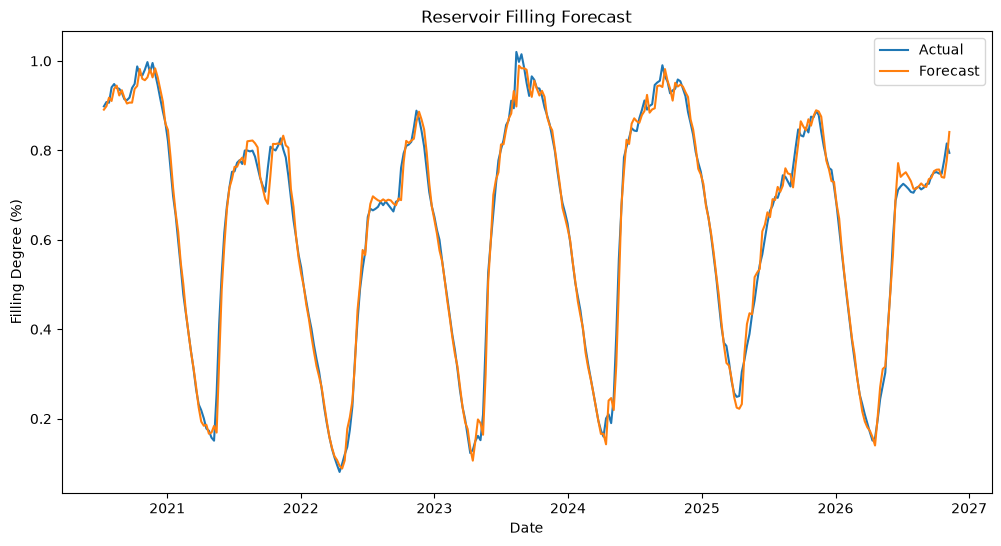

In [10]:
plt.figure(figsize=(12, 6))

plt.plot(
    test["dato_Id"],
    y_test,
    label="Actual"
)

plt.plot(
    test["dato_Id"],
    predictions,
    label="Forecast"
)

plt.title(
    "Reservoir Filling Forecast"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Filling Degree (%)"
)

plt.legend()

plt.show()


In [13]:
def forecast_reservoir(
    dataframe,
    history_length=260,
    forecast_horizon=12,
    lags=[1, 2, 4, 8],
    n_estimators=200
):
    """
    Forecast reservoir filling using a lag-based
    Random Forest model.

    Parameters
    ----------
    dataframe : pd.DataFrame
        Magasinstatistikk data for a selected area.

    history_length : int
        Number of most recent observations used
        when training the model.

    forecast_horizon : int
        Number of observations reserved for testing
        and evaluation.

    lags : list
        Historical lag values used as predictors.

    n_estimators : int
        Number of trees in the Random Forest model.

    Returns
    -------
    dict
        Model results and evaluation metrics.
    """

    df = dataframe.copy()

    # --------------------------------------------------
    # Restrict history length
    # --------------------------------------------------

    df = df.tail(
        history_length
    )

    # --------------------------------------------------
    # Create lag predictors
    # --------------------------------------------------

    for lag in lags:

        df[f"lag_{lag}"] = (
            df["fyllingsgrad"]
            .shift(lag)
        )

    df = df.dropna()

    # --------------------------------------------------
    # Chronological train/test split
    # --------------------------------------------------

    train = df.iloc[
        :-forecast_horizon
    ]

    test = df.iloc[
        -forecast_horizon:
    ]

    feature_columns = [
        f"lag_{lag}"
        for lag in lags
    ]

    X_train = train[
        feature_columns
    ]

    y_train = train[
        "fyllingsgrad"
    ]

    X_test = test[
        feature_columns
    ]

    y_test = test[
        "fyllingsgrad"
    ]

    # --------------------------------------------------
    # Train model
    # --------------------------------------------------

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------
    # Generate forecast
    # --------------------------------------------------

    predictions = model.predict(
        X_test
    )

    # --------------------------------------------------
    # Evaluate forecast performance
    # --------------------------------------------------

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        np.mean(
            (y_test - predictions) ** 2
        )
    )

    # --------------------------------------------------
    # Return results
    # --------------------------------------------------

    return {
        "model": model,
        "predictions": predictions,
        "actual": y_test,
        "dates": test["dato_Id"],
        "mae": mae,
        "rmse": rmse,
        "history_length": history_length,
        "forecast_horizon": forecast_horizon,
        "lags": lags
    }

In [15]:
result_1 = forecast_reservoir(
    forecast_df,
    history_length=104,
    forecast_horizon=12,
    lags=[1, 2, 4, 8]
)

print(
    f"MAE: {result_1['mae']:.2f}"
)

print(
    f"RMSE: {result_1['rmse']:.2f}"
)

MAE: 0.02
RMSE: 0.02


In [16]:
result_2 = forecast_reservoir(
    forecast_df,
    history_length=156,
    forecast_horizon=12,
    lags=[1, 2, 4, 8]
)

print(
    f"MAE: {result_2['mae']:.2f}"
)

print(
    f"RMSE: {result_2['rmse']:.2f}"
)

MAE: 0.02
RMSE: 0.03


In [17]:
result_3 = forecast_reservoir(
    forecast_df,
    history_length=260,
    forecast_horizon=12,
    lags=[1, 2, 4, 8]
)

print(
    f"MAE: {result_3['mae']:.2f}"
)

print(
    f"RMSE: {result_3['rmse']:.2f}"
)

MAE: 0.02
RMSE: 0.03


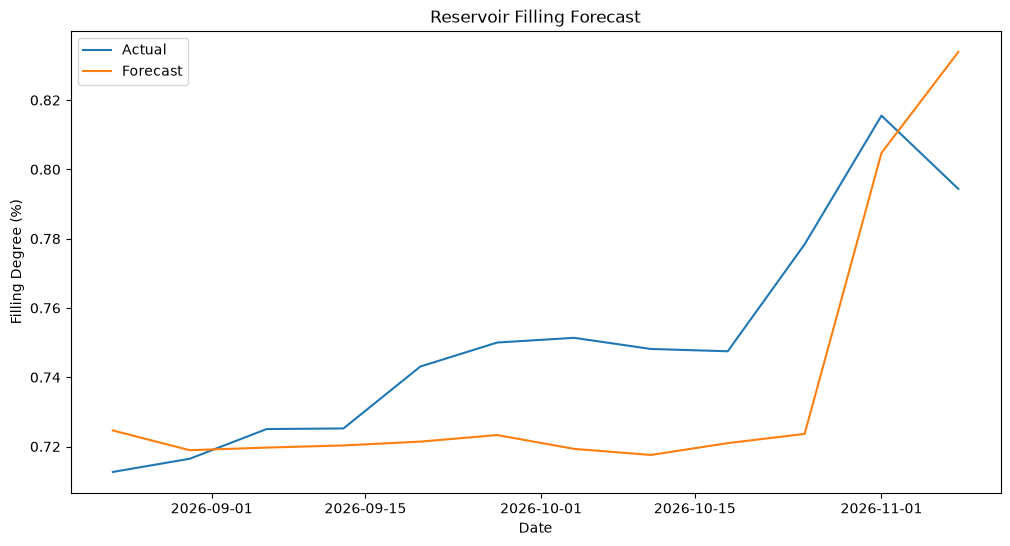

In [18]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    result_3["dates"],
    result_3["actual"],
    label="Actual"
)

plt.plot(
    result_3["dates"],
    result_3["predictions"],
    label="Forecast"
)

plt.title(
    "Reservoir Filling Forecast"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Filling Degree (%)"
)

plt.legend()

plt.show()

In [19]:
print(
    f"History Length: {result_3['history_length']}"
)

print(
    f"Forecast Horizon: {result_3['forecast_horizon']}"
)

print(
    f"MAE: {result_3['mae']:.4f}"
)

print(
    f"RMSE: {result_3['rmse']:.4f}"
)

History Length: 260
Forecast Horizon: 12
MAE: 0.0223
RMSE: 0.0270


### Forecast Findings

A lag-based Random Forest model was implemented to
forecast reservoir filling using historical filling
degree observations as input features.

The model was able to reproduce the overall behaviour
of the reservoir filling series and capture the main
trends observed in the historical data.

Model Validation showed that the forecasts generally
followed the observed development of the filling degree,
although deviations occurred during periods of rapid
change. Some underestimation was observed during strong
growth periods, while slight overestimation appeared in
parts of the forecast horizon.

The forecasting interface allows the user to adjust
history length, forecast horizon, lag structure,
ensemble size and optional weather variables. Several
parameter combinations were tested to evaluate model
behaviour and responsiveness.

Future Forecast functionality was implemented to
generate forecasts beyond the available observations.
A seasonal stabilisation approach was added to avoid the
unrealistically flat forecasts produced by a purely
recursive prediction strategy.

The Random Forest approach was selected because it is
computationally efficient, works well with lagged
features, and supports interactive parameter tuning
within the Streamlit application.

Possible future improvements include testing additional
lag structures, incorporating economic or electricity
market variables, and comparing the results against a
SARIMAX-based forecasting approach.

## Correlation analysis

The purpose of this section is to investigate the relationship between reservoir filling and weather conditions.

Two meteorological variables are considered:

Temperature
Precipitation
The analysis investigates:

Overall correlations
Lagged correlations
Rolling correlations
The findings will later be transferred to the Streamlit application.

In [1]:
import pandas as pd
import numpy as np
import requests

import matplotlib.pyplot as plt

Reservoir filling observations are downloaded directly from the Magasinstatistikk API.

In [2]:
url = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

reservoir_df = pd.DataFrame(
    requests.get(url).json()
)

The analysis is performed for EL1 as an example. The same workflow can later be reused for all other areas.

In [3]:
reservoir_df = reservoir_df[
    (reservoir_df["omrType"] == "EL")
    &
    (reservoir_df["omrnr"] == 1)
].copy()

reservoir_df["dato_Id"] = pd.to_datetime(
    reservoir_df["dato_Id"]
)

reservoir_df = reservoir_df.sort_values(
    "dato_Id"
)

reservoir_df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
7718,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
8060,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,0001-01-01T00:00:00,0.617574,-0.038369
8109,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,0001-01-01T00:00:00,0.579205,-0.032491
7970,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,0001-01-01T00:00:00,0.546713,-0.042168
7780,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,0001-01-01T00:00:00,0.504545,-0.039210


### Download Weather Data

Historical weather observations are downloaded
from Open-Meteo.

The coordinates correspond to the representative
location previously used for EL1.

In [4]:
weather_url = (
    "https://archive-api.open-meteo.com/v1/archive"
)

params = {
    "latitude": 59.91,
    "longitude": 10.75,
    "start_date": "2010-01-01",
    "end_date": "2024-12-31",
    "daily": [
        "temperature_2m_mean",
        "precipitation_sum"
    ],
    "timezone": "auto"
}

weather_data = requests.get(
    weather_url,
    params=params
).json()

In [5]:
weather_df = pd.DataFrame(
    {
        "dato_Id": pd.to_datetime(
            weather_data["daily"]["time"]
        ),
        "temperature": weather_data["daily"][
            "temperature_2m_mean"
        ],
        "precipitation": weather_data["daily"][
            "precipitation_sum"
        ]
    }
)

weather_df.head()

,dato_Id,temperature,precipitation
0,2010-01-01,-9.7,0.3
1,2010-01-02,-12.9,0.0
2,2010-01-03,-18.3,0.0
3,2010-01-04,-17.0,0.0
4,2010-01-05,-18.4,0.4


### Align Time Resolution

Magasinstatistikk data are weekly while weather
data are daily.

The reservoir observations are interpolated to
daily values before correlation analysis.

In [6]:
reservoir_daily = (
    reservoir_df
    .set_index("dato_Id")
    [["fyllingsgrad"]]
    .resample("D")
    .interpolate()
    .reset_index()
)

reservoir_daily.head()

,dato_Id,fyllingsgrad
0,1995-01-08,0.617574
1,1995-01-09,0.612092
2,1995-01-10,0.606611
3,1995-01-11,0.601130
4,1995-01-12,0.595648


### Merge Datasets

Weather observations and reservoir filling
observations are merged by date.

In [7]:
merged_df = pd.merge(
    reservoir_daily,
    weather_df,
    on="dato_Id",
    how="inner"
)

merged_df.head()

,dato_Id,fyllingsgrad,temperature,precipitation
0,2010-01-01,0.608771,-9.7,0.3
1,2010-01-02,0.602465,-12.9,0.0
2,2010-01-03,0.596159,-18.3,0.0
3,2010-01-04,0.588798,-17.0,0.0
4,2010-01-05,0.581436,-18.4,0.4


### Overall Correlations

Calculate simple Pearson correlations between
reservoir filling and weather variables.


In [8]:
correlation_table = merged_df[
    [
        "fyllingsgrad",
        "temperature",
        "precipitation"
    ]
].corr()

correlation_table

,fyllingsgrad,temperature,precipitation
fyllingsgrad,1.000000,0.350745,0.116075
temperature,0.350745,1.000000,0.118179
precipitation,0.116075,0.118179,1.000000


### Lag Correlation Analysis

Weather conditions may affect reservoir filling
after a delay.

The following function calculates correlations
for a range of lag values.

In [9]:
def lag_correlation(
    dataframe,
    weather_variable,
    max_lag=30
):

    results = []

    for lag in range(
        -max_lag,
        max_lag + 1
    ):

        shifted = dataframe[
            weather_variable
        ].shift(lag)

        corr = dataframe[
            "fyllingsgrad"
        ].corr(
            shifted
        )

        results.append(
            {
                "lag": lag,
                "correlation": corr
            }
        )

    return pd.DataFrame(
        results
    )

In [10]:
temperature_corr = lag_correlation(
    merged_df,
    "temperature",
    max_lag=30
)

temperature_corr.head()

,lag,correlation
0,-30,-0.083261
1,-29,-0.068988
2,-28,-0.054650
3,-27,-0.040221
4,-26,-0.025692


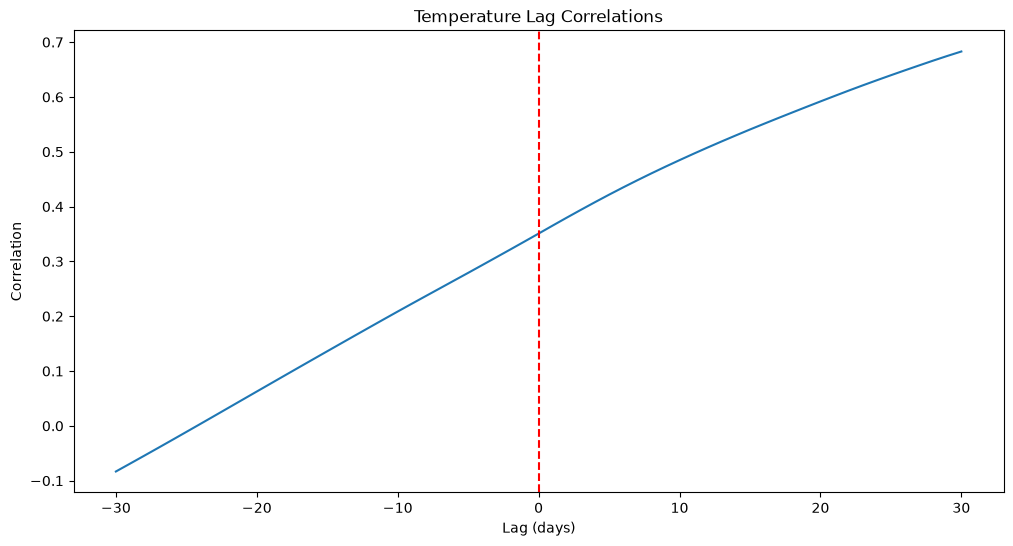

In [11]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    temperature_corr["lag"],
    temperature_corr["correlation"]
)

plt.axvline(
    0,
    linestyle="--",
    color="red"
)

plt.title(
    "Temperature Lag Correlations"
)

plt.xlabel(
    "Lag (days)"
)

plt.ylabel(
    "Correlation"
)

plt.show()

In [12]:
precip_corr = lag_correlation(
    merged_df,
    "precipitation",
    max_lag=30
)


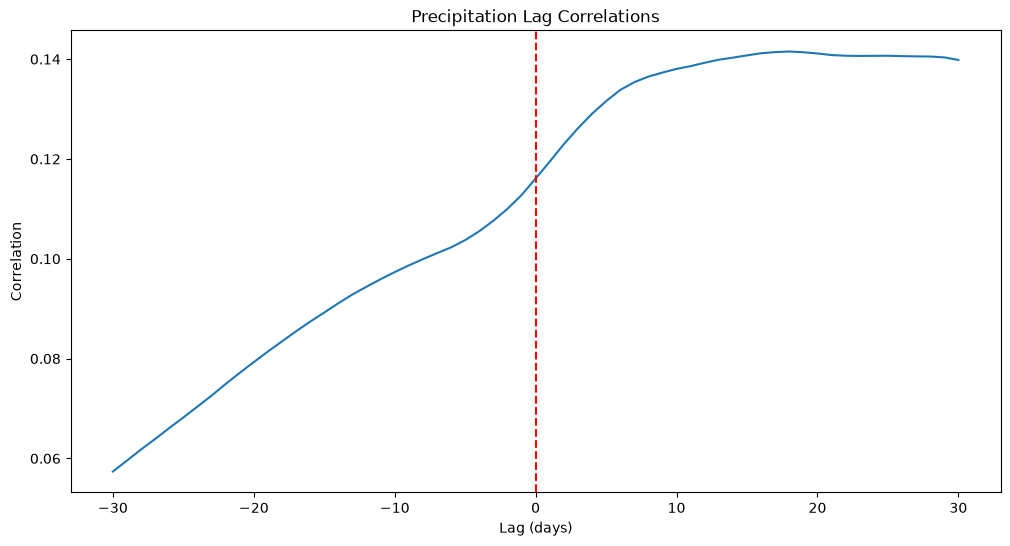

In [13]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    precip_corr["lag"],
    precip_corr["correlation"]
)

plt.axvline(
    0,
    linestyle="--",
    color="red"
)

plt.title(
    "Precipitation Lag Correlations"
)

plt.xlabel(
    "Lag (days)"
)

plt.ylabel(
    "Correlation"
)

plt.show()

### Rolling Correlation

A rolling correlation is used to investigate
whether the relationship between weather and
reservoir filling changes over time.

In [14]:
window_length = 90

rolling_corr = (
    merged_df["fyllingsgrad"]
    .rolling(window_length)
    .corr(
        merged_df["temperature"]
    )
)

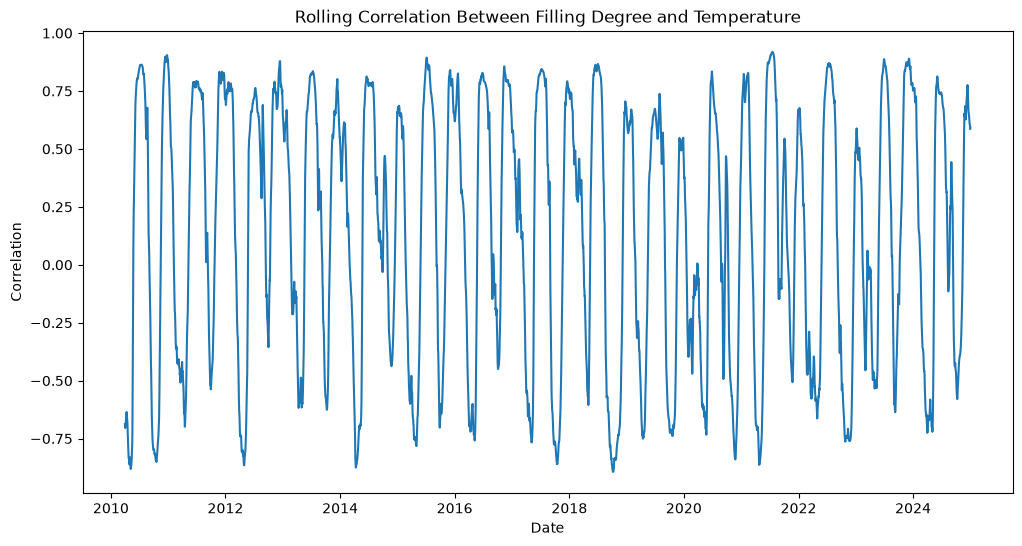

In [15]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    merged_df["dato_Id"],
    rolling_corr
)

plt.title(
    "Rolling Correlation Between Filling Degree and Temperature"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Correlation"
)

plt.show()

### Correlation Findings

The correlation analysis demonstrated that the observed
relationship between weather variables and reservoir
filling varies over time and depends on both lag length
and rolling window size.

Testing different lag values showed that the strongest
relationships did not always occur at lag 0, indicating
that weather conditions may influence reservoir filling
with a delay. This behaviour was particularly visible
when comparing different weather variables and lag
settings.

Short rolling windows reacted quickly to local changes
but produced more volatile correlation patterns. Larger
window sizes generated smoother and more stable results,
making long-term relationships easier to identify.

During testing, temperature generally produced more
stable correlation patterns than precipitation, although
the strength of the relationship varied depending on the
selected area and analysis settings. This suggests that
weather variables may provide useful information for
reservoir forecasting when combined with historical
filling data.

The implemented controls made it possible to explore
how lag assumptions and temporal aggregation influence
observed relationships between weather conditions and
reservoir filling.

## Project Log

Part 4 was the largest and most demanding stage of the project. While earlier stages mainly focused on collecting, cleaning and analysing data, this stage focused on bringing the different components together into a complete application.

The work started with the implementation of the Norges Bank API and a timezone investigation involving Magasinstatistikk, ENTSO-E, Open-Meteo and Norges Bank data. The investigation highlighted differences in data resolution and reporting practices, which helped establish a consistent approach for handling dates and time series throughout the project.

One of the most important decisions during this part was the introduction of shared Session State. Feedback from the previous assignment highlighted the importance of using the same area selection across the application. This resulted in a common area selection system that is now reused in Reservoir Analysis, Weather Analysis, Correlation Analysis, Forecasting and the Interactive Map.

A large amount of time was spent developing forecasting functionality. A lag-based machine learning model using Random Forest regression was implemented and tested using different history lengths, forecast horizons, lag combinations and optional weather variables. The forecasting page was expanded to support both Model Validation and Future Forecast modes. Additional work was required to improve forecast behaviour, avoid unrealistic forecasts and make the interface easier to understand through explanatory text and interactive controls.

The interactive map became one of the most challenging parts of the assignment. The final solution combines GeoJSON visualisation, time-dependent map layers, weather and reservoir properties, and clickable map regions that update area selections throughout the application. Considerable effort was spent integrating the map with Session State so that user selections automatically propagate across analyses.

Several pages were refactored based on feedback and testing. The Weather Analysis page was updated to use the same area selection logic as Magasinstatistikk, following teacher feedback from the previous assignment. The Crossborder Flow page was redesigned from static matplotlib figures to interactive Plotly visualisations and reorganised to match the structure and appearance of the rest of the application. Data quality checks also revealed missing observations in the ENTSO-E dataset, and the visualisation was adjusted to display gaps instead of potentially misleading continuous lines.

The overall application structure was also revisited during development. The original pages were reorganised into Data Overview, Analysis, Forecasting and Electricity-related functionality, in line with the architecture sketch created at the beginning of the assignment. Data Table and Plot functionality were merged into a common Data Overview page to improve usability and reduce duplication.

A consistent visual style was maintained throughout the application. Plotly White was selected as the common theme for visualisations, and all pages were redesigned to follow a similar structure with introductions, controls, interactive graphics and supporting explanations. This contributed to a more consistent and user-friendly application than the versions developed in previous project parts.

## AI Usage

I acknowledge the use of Microsoft 365 Copilot (https://www.microsoft.com/copilot), based on the GPT-5 chat model, during this part of the project.

Microsoft 365 Copilot was used as a development assistant throughout the implementation of Part 4. AI support was primarily used for debugging Streamlit applications, reviewing forecasting models, improving interactive visualisations, restructuring pages, implementing session state functionality, developing GeoJSON-based map solutions, and improving code readability through comments and documentation.

AI assistance was also used to discuss design decisions, verify interpretations of project requirements, identify inconsistencies between the Streamlit application and the Notebook documentation, and suggest improvements related to user experience and application structure.

All generated code, explanations, and recommendations were reviewed, tested, modified, and integrated by the student before use. Final implementation decisions, analysis, interpretation of results, and conclusions remain the student's own responsibility.